# Temperature Sensor Analysis and Fusion

Calculate the mean and variance for each sensor from a calibration log. Test basic averaging vs. inverse-variance weighting to fuse the sensors. Use the factory-calibrated TMP117 readings as the assumed ground truth. 

Press `shift + enter` to run each cell.

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import utils

## Settings

In [2]:
# Recording (folders containing temp.csv and meta.json)
RECORDING_CAL_PATH = "recordings/static_cal"
RECORDING_EVAL_PATH = "recordings/static_eval"

## Analyze Calibration Data

In [3]:
# Load both recordings
cal, cal_meta = utils.load_recording(RECORDING_CAL_PATH)
ev, ev_meta = utils.load_recording(RECORDING_EVAL_PATH)
print(f"Num calibration samples: {cal["t_us"].shape}")
print(f"Num evaluation samples: {ev["t_us"].shape}")

Num calibration samples: (301,)
Num evaluation samples: (301,)


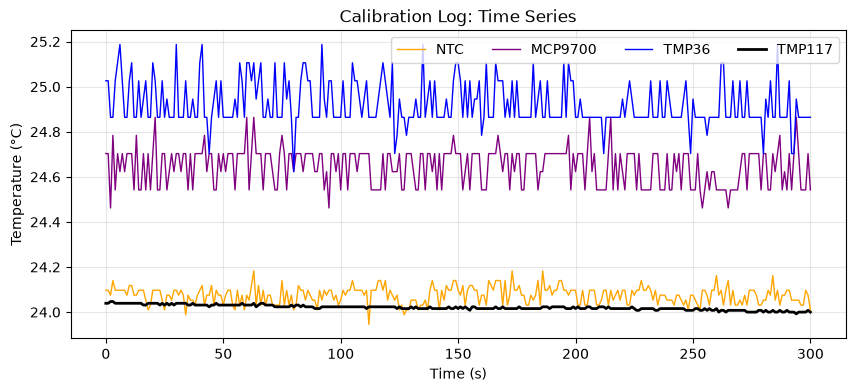

In [4]:
# Plot sensor values over time
utils.plot_series(
    cal["t"],
    [
        ("NTC", cal['ntc_c'], "orange"),
        ("MCP9700", cal['mcp9700_c'], "purple"),
        ("TMP36", cal['tmp36_c'], "blue"),
        ("TMP117", cal['tmp117_c'], "k"),
    ],
    title="Calibration Log: Time Series",
)

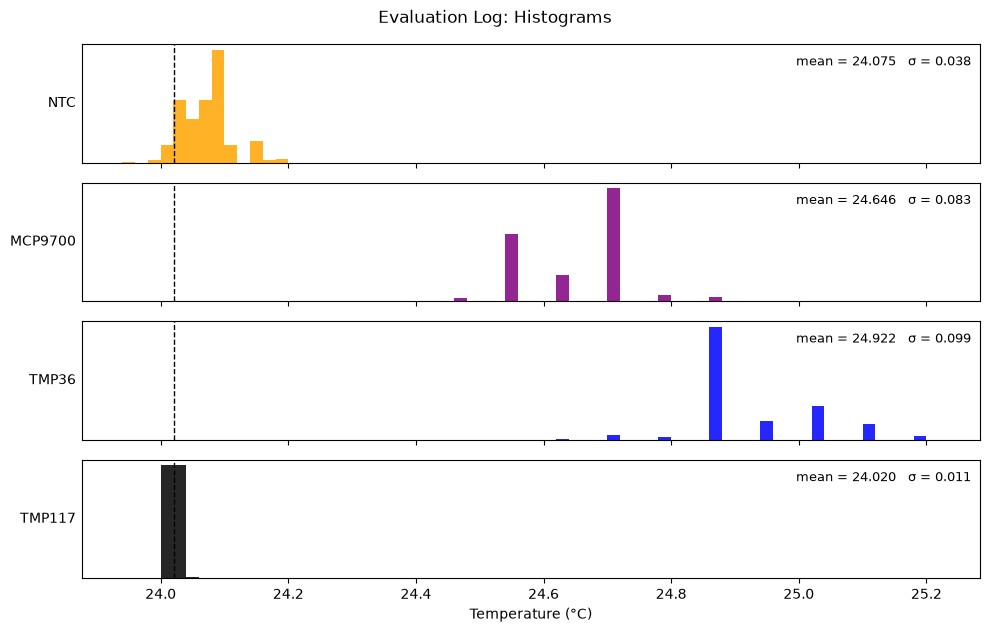

In [8]:
# Plot histograms of sensor values
utils.plot_histograms(
    [
        ("NTC", cal['ntc_c'], "orange"),
        ("MCP9700", cal['mcp9700_c'], "purple"),
        ("TMP36", cal['tmp36_c'], "blue"),
        ("TMP117", cal['tmp117_c'], "k"),
    ],
    ref_value=np.mean(cal['tmp117_c']),
    title="Evaluation Log: Histograms",
    xlabel="Temperature (°C)",
)

In [9]:
# Print means and standard deviations
print(f"NTC mean: {np.mean(cal['ntc_c']):.3f} std dev: {np.std(cal['ntc_c']):.3f}")
print(f"MCP9700 mean: {np.mean(cal['mcp9700_c']):.3f} std dev: {np.std(cal['mcp9700_c']):.3f}")
print(f"TMP36 mean: {np.mean(cal['tmp36_c']):.3f} std dev: {np.std(cal['tmp36_c']):.3f}")
print(f"TMP117 mean: {np.mean(cal['tmp117_c']):.3f} std dev: {np.std(cal['tmp117_c']):.3f}")

NTC mean: 24.075 std dev: 0.038
MCP9700 mean: 24.646 std dev: 0.083
TMP36 mean: 24.922 std dev: 0.099
TMP117 mean: 24.020 std dev: 0.011


## Use the Evaluation Data for Testing

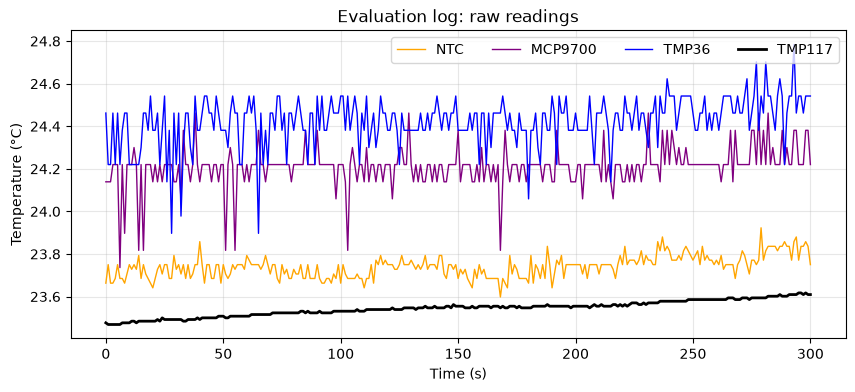

In [10]:
# Plot sensor values over time
utils.plot_series(
    cal["t"],
    [
        ("NTC", ev['ntc_c'], "orange"),
        ("MCP9700", ev['mcp9700_c'], "purple"),
        ("TMP36", ev['tmp36_c'], "blue"),
        ("TMP117", ev['tmp117_c'], "k"),
    ],
    title="Evaluation log: raw readings",
)

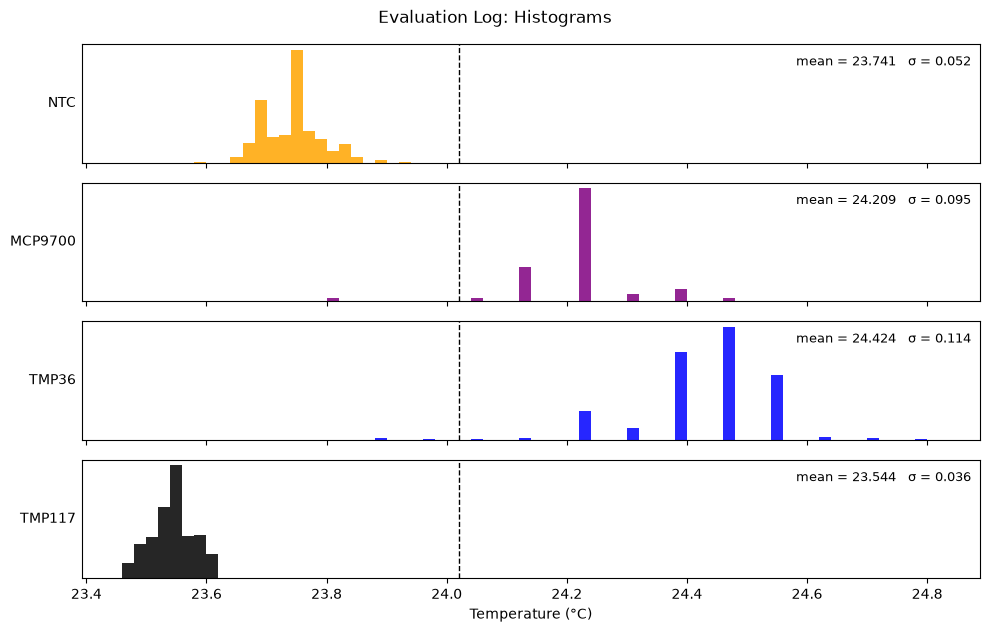

In [12]:
# Plot histograms of sensor values
utils.plot_histograms(
    [
        ("NTC", ev['ntc_c'], "orange"),
        ("MCP9700", ev['mcp9700_c'], "purple"),
        ("TMP36", ev['tmp36_c'], "blue"),
        ("TMP117", ev['tmp117_c'], "k"),
    ],
    ref_value=np.mean(cal['tmp117_c']),
    title="Evaluation Log: Histograms",
    xlabel="Temperature (°C)",
)

## Calibrate Against the TMP117

In [13]:
# Find the average bias (offset) for each sensor vs. TMP117
ntc_offset = np.mean(cal['ntc_c'] - cal['tmp117_c'])
mcp_offset = np.mean(cal['mcp9700_c'] - cal['tmp117_c'])
tmp_offset = np.mean(cal['tmp36_c'] - cal['tmp117_c'])

# Print offsets
print(f"NTC offset: {ntc_offset:.4f}")
print(f"MCP9700 offset: {mcp_offset:.4f}")
print(f"TMP36 offset: {tmp_offset:.4f}")

NTC offset: 0.0548
MCP9700 offset: 0.6260
TMP36 offset: 0.9011


In [14]:
# Apply the offsets to the evaluation log
ntc_ev_cal = ev['ntc_c'] - ntc_offset
mcp_ev_cal = ev['mcp9700_c'] - mcp_offset
tmp_ev_cal = ev['tmp36_c'] - tmp_offset

# Get the evaluation TMP117 data as ref_everence
ref_ev = ev['tmp117_c']

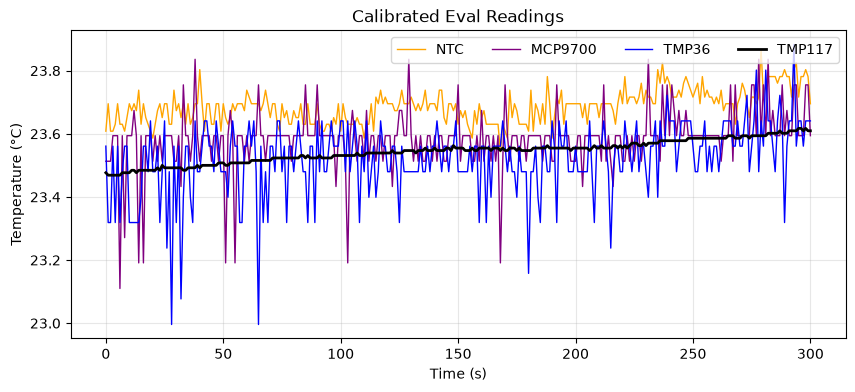

In [15]:
# Plot calibrated sensor values vs. original TMP117
utils.plot_series(
    ev["t"],
    [
        ("NTC", ntc_ev_cal, "orange"),
        ("MCP9700", mcp_ev_cal, "purple"),
        ("TMP36", tmp_ev_cal, "blue"),
        ("TMP117", ref_ev, "k"),
    ],
    title="Calibrated Eval Readings",
)

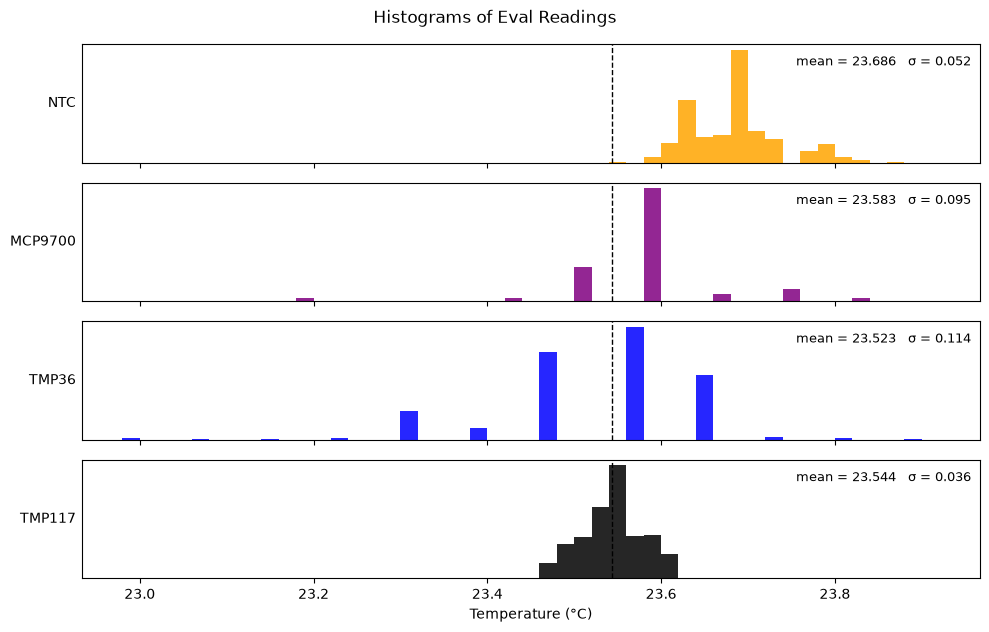

In [16]:
# Plot histograms of calibrated sensor values
utils.plot_histograms(
    [
        ("NTC", ntc_ev_cal, "orange"),
        ("MCP9700", mcp_ev_cal, "purple"),
        ("TMP36", tmp_ev_cal, "blue"),
        ("TMP117", ref_ev, "k"),
    ],
    ref_value=np.mean(ref_ev),
    title="Histograms of Eval Readings",
    xlabel="Temperature (°C)",
)

## Fusion: Simple Averaging

In [25]:
# Simply average across the different sensors with the calibrated eval data
avgs_ev_cal = np.mean([ntc_ev_cal, mcp_ev_cal, tmp_ev_cal], axis=0)

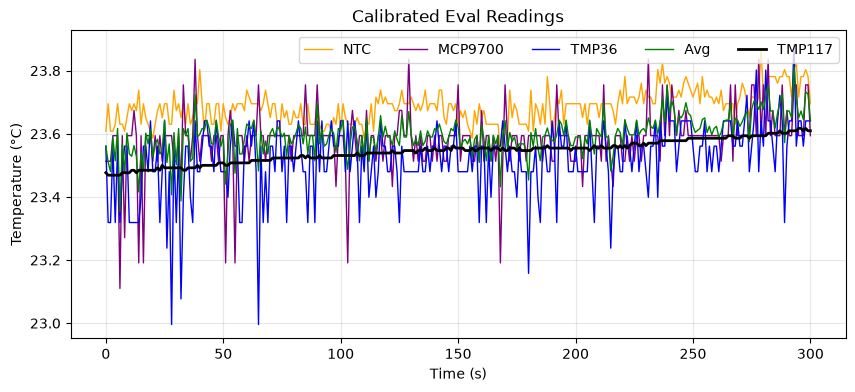

In [26]:
# Plot calibrated sensor values vs. averaging fusion vs. original TMP117
utils.plot_series(
    ev["t"],
    [
        ("NTC", ntc_ev_cal, "orange"),
        ("MCP9700", mcp_ev_cal, "purple"),
        ("TMP36", tmp_ev_cal, "blue"),
        ("Avg", avgs_ev_cal, "green"),
        ("TMP117", ref_ev, "k"),
    ],
    title="Calibrated Eval Readings",
)

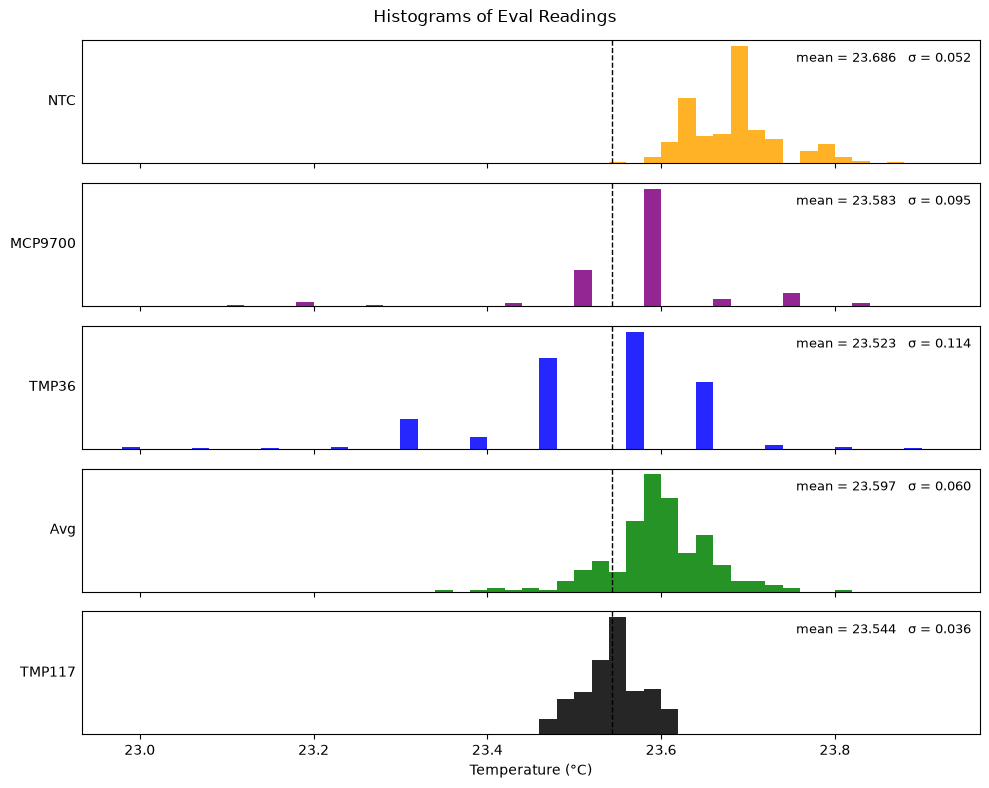

In [27]:
# Plot histograms of calibrated sensor values
utils.plot_histograms(
    [
        ("NTC", ntc_ev_cal, "orange"),
        ("MCP9700", mcp_ev_cal, "purple"),
        ("TMP36", tmp_ev_cal, "blue"),
        ("Avg", avgs_ev_cal, "green"),
        ("TMP117", ref_ev, "k"),
    ],
    ref_value=np.mean(ref_ev),
    title="Histograms of Eval Readings",
    xlabel="Temperature (°C)",
)

In [28]:
# Print mean and std devs for calibrated data
print(f"Calibrated NTC mean: {np.mean(ntc_ev_cal):.3f} std dev: {np.std(ntc_ev_cal, ddof=1):.3f}")
print(f"Calibrated MCP9700 mean: {np.mean(mcp_ev_cal):.3f} std dev: {np.std(mcp_ev_cal, ddof=1):.3f}")
print(f"Calibrated TMP36 mean: {np.mean(tmp_ev_cal):.3f} std dev: {np.std(tmp_ev_cal, ddof=1):.3f}")
print(f"Calibrated Avg Fusion mean: {np.mean(avgs_ev_cal):.3f} std dev: {np.std(avgs_ev_cal, ddof=1):.3f}")
print(f"TMP117 mean: {np.mean(ref_ev):.3f} std dev: {np.std(ref_ev, ddof=1):.3f}")

Calibrated NTC mean: 23.686 std dev: 0.052
Calibrated MCP9700 mean: 23.583 std dev: 0.095
Calibrated TMP36 mean: 23.523 std dev: 0.114
Calibrated Avg Fusion mean: 23.597 std dev: 0.060
TMP117 mean: 23.544 std dev: 0.036


## Fusion: Inverse-Variance Weighting

In [29]:
# Find the noise (std dev of error vs. TMP117) for each sensor on the cal log
ntc_sigma = np.std(cal["ntc_c"] - cal["tmp117_c"], ddof=1)
mcp_sigma = np.std(cal["mcp9700_c"] - cal["tmp117_c"], ddof=1)
tmp_sigma = np.std(cal["tmp36_c"] - cal["tmp117_c"], ddof=1)

# Print noise levels
print(f"NTC sigma: {ntc_sigma:.4f}")
print(f"MCP9700 sigma: {mcp_sigma:.4f}")
print(f"TMP36 sigma: {tmp_sigma:.4f}")

NTC sigma: 0.0382
MCP9700 sigma: 0.0824
TMP36 sigma: 0.0972


In [30]:
# Inverse variance: quieter sensors get a bigger vote
ntc_iv = 1 / ntc_sigma**2
mcp_iv = 1 / mcp_sigma**2
tmp_iv = 1 / tmp_sigma**2
iv_sum = ntc_iv + mcp_iv + tmp_iv

# Normalize so the weights add up to 1
ntc_w = ntc_iv / iv_sum
mcp_w = mcp_iv / iv_sum
tmp_w = tmp_iv / iv_sum

# Print weights
print(f"NTC weight: {ntc_w:.3f}")
print(f"MCP9700 weight: {mcp_w:.3f}")
print(f"TMP36 weight: {tmp_w:.3f}")

NTC weight: 0.730
MCP9700 weight: 0.157
TMP36 weight: 0.113


In [34]:
# Fuse the calibrated eval data with the weights
ivw_ev_cal = ntc_w * ntc_ev_cal + mcp_w * mcp_ev_cal + tmp_w * tmp_ev_cal

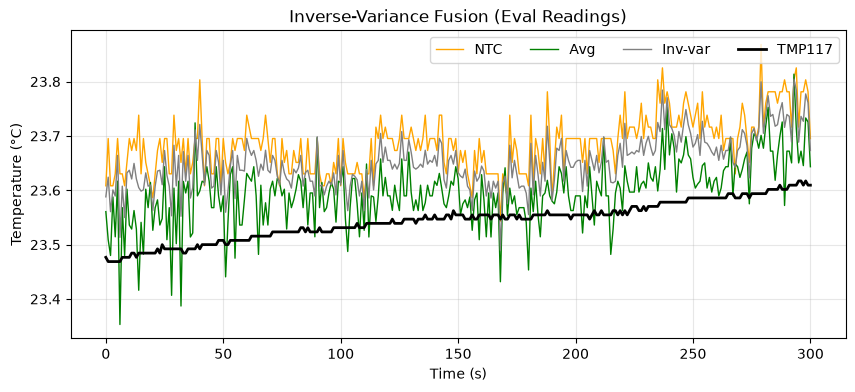

In [36]:
# Plot calibrated NTC vs. averaging vs. inverse-variance vs. TMP117
utils.plot_series(
    ev["t"],
    [
        ("NTC", ntc_ev_cal, "orange"),
        ("Avg", avgs_ev_cal, "green"),
        ("Inv-var", ivw_ev_cal, "gray"),
        ("TMP117", ref_ev, "k"),
    ],
    title="Inverse-Variance Fusion (Eval Readings)",
)

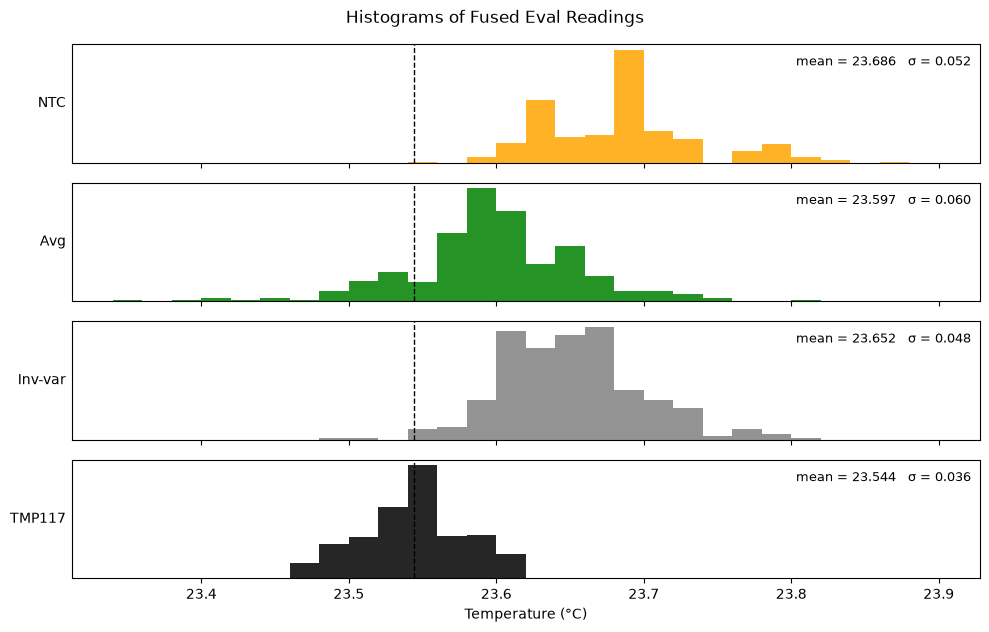

In [38]:
# Plot histograms of the fused results vs. the best single sensor
utils.plot_histograms(
    [
        ("NTC", ntc_ev_cal, "orange"),
        ("Avg", avgs_ev_cal, "green"),
        ("Inv-var", ivw_ev_cal, "gray"),
        ("TMP117", ref_ev, "k"),
    ],
    ref_value=np.mean(ref_ev),
    title="Histograms of Fused Eval Readings",
    xlabel="Temperature (°C)",
)

In [39]:
# Print mean and std devs for calibrated data
print(f"Calibrated NTC mean: {np.mean(ntc_ev_cal):.3f} std dev: {np.std(ntc_ev_cal, ddof=1):.3f}")
print(f"Calibrated Avg Fusion mean: {np.mean(avgs_ev_cal):.3f} std dev: {np.std(avgs_ev_cal, ddof=1):.3f}")
print(f"Calibrated IVW Fusion mean: {np.mean(ivw_ev_cal):.3f} std dev: {np.std(ivw_ev_cal, ddof=1):.3f}")
print(f"TMP117 mean: {np.mean(ref_ev):.3f} std dev: {np.std(ref_ev, ddof=1):.3f}")

Calibrated NTC mean: 23.686 std dev: 0.052
Calibrated Avg Fusion mean: 23.597 std dev: 0.060
Calibrated IVW Fusion mean: 23.652 std dev: 0.048
TMP117 mean: 23.544 std dev: 0.036
